# Day 2 — Customer Segmentation
## Uber Eats Operational & Customer Intelligence System



## 1. Import libraries and set project paths


In [5]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT_ROOT / "data" / "raw"
PROCESSED = PROJECT_ROOT / "data" / "processed"
OUTPUTS = PROJECT_ROOT / "outputs" / "customer_segmentation"
MODELS = PROJECT_ROOT / "models"

for folder in [PROCESSED, OUTPUTS, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Raw data folder exists:", RAW.exists())

Project root: /home/nineleaps/Downloads/uber_eats-ML
Raw data folder exists: True


## 2. Load and inspect the data

Check row counts, columns, data types, and missing values before creating features.

In [6]:
customers = pd.read_csv(RAW / "customers.csv")
orders = pd.read_csv(RAW / "orders.csv", parse_dates=["order_timestamp"])
reviews = pd.read_csv(RAW / "reviews.csv", parse_dates=["review_timestamp"])

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Reviews:", reviews.shape)

display(customers.head())
display(orders.head())
display(reviews.head())

Customers: (300, 5)
Orders: (1800, 8)
Reviews: (1147, 6)


,customer_id,age,gender,city,signup_date
0,CUST0001,22,Male,Pune,2023-01-06
1,CUST0002,55,Prefer not to say,Pune,2023-02-25
2,CUST0003,49,Female,Pune,2023-10-12
3,CUST0004,39,Prefer not to say,Hyderabad,2026-02-23
4,CUST0005,38,Non-binary,Mumbai,2024-08-19


,order_id,customer_id,restaurant_id,order_timestamp,order_amount_inr,number_of_items,preparation_time_minutes,order_status
0,ORD00001,CUST0296,REST007,2026-02-05 11:57:00,676.47,4,16,Failed
1,ORD00002,CUST0194,REST012,2026-02-06 19:41:00,387.77,1,24,Delivered
2,ORD00003,CUST0264,REST044,2026-02-20 21:24:00,460.51,1,33,Delivered
3,ORD00004,CUST0194,REST008,2026-02-18 08:38:00,797.93,4,22,Delivered
4,ORD00005,CUST0114,REST041,2026-01-10 12:50:00,1007.59,3,15,Delivered


,review_id,order_id,customer_id,rating,review_text,review_timestamp
0,REV00001,ORD00002,CUST0194,5,Quick delivery and friendly driver.,2026-02-09 19:41:00
1,REV00002,ORD00003,CUST0264,5,Food arrived hot and tasted great.,2026-02-23 21:24:00
2,REV00003,ORD00004,CUST0194,4,Food arrived hot and tasted great.,2026-02-21 08:38:00
3,REV00004,ORD00005,CUST0114,4,Quick delivery and friendly driver.,2026-01-12 12:50:00
4,REV00005,ORD00006,CUST0124,2,Order was missing an item.,2026-03-11 15:21:00


In [7]:
print("Missing values in customers:")
display(customers.isna().sum())

print("Missing values in orders:")
display(orders.isna().sum())

print("Missing values in reviews:")
display(reviews.isna().sum())

print("Order status values:")
display(orders["order_status"].value_counts(dropna=False))

Missing values in customers:


customer_id    0
age            0
gender         0
city           0
signup_date    0
dtype: int64

Missing values in orders:


order_id                    0
customer_id                 0
restaurant_id               0
order_timestamp             0
order_amount_inr            0
number_of_items             0
preparation_time_minutes    0
order_status                0
dtype: int64

Missing values in reviews:


review_id           0
order_id            0
customer_id         0
rating              0
review_text         0
review_timestamp    0
dtype: int64

Order status values:


order_status
Delivered    1624
Cancelled     135
Failed         41
Name: count, dtype: int64

## 3. Feature engineering

Create one row per customer with:
- total orders
- average order value and total spending from delivered orders
- ordering frequency (orders per active month)
- average rating given
- weekend orders
- late-night orders (10 PM to before 5 AM)

`customer_id` is retained only to identify each row in the exported dataset. It is **not** included in the model features.

In [8]:
orders["order_date"] = orders["order_timestamp"].dt.date
orders["order_hour"] = orders["order_timestamp"].dt.hour
orders["is_weekend"] = orders["order_timestamp"].dt.dayofweek >= 5
orders["is_late_night"] = (orders["order_hour"] >= 22) | (orders["order_hour"] < 5)

# All order attempts count toward total orders and ordering frequency.
order_summary = orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    first_order=("order_timestamp", "min"),
    last_order=("order_timestamp", "max"),
    weekend_orders=("is_weekend", "sum"),
    late_night_orders=("is_late_night", "sum")
).reset_index()

# Spend and average order value use delivered orders only.
delivered = orders[orders["order_status"].astype(str).str.lower().eq("delivered")].copy()
spend_summary = delivered.groupby("customer_id").agg(
    total_spending=("order_amount_inr", "sum"),
    average_order_value=("order_amount_inr", "mean")
).reset_index()

rating_summary = reviews.groupby("customer_id").agg(
    average_rating_given=("rating", "mean")
).reset_index()

customer_features = customers[["customer_id", "age", "gender", "city"]].merge(
    order_summary, on="customer_id", how="left"
).merge(spend_summary, on="customer_id", how="left").merge(
    rating_summary, on="customer_id", how="left"
)

customer_features["total_orders"] = customer_features["total_orders"].fillna(0)
customer_features["weekend_orders"] = customer_features["weekend_orders"].fillna(0)
customer_features["late_night_orders"] = customer_features["late_night_orders"].fillna(0)
customer_features["total_spending"] = customer_features["total_spending"].fillna(0)
customer_features["average_order_value"] = customer_features["average_order_value"].fillna(0)
customer_features["average_rating_given"] = customer_features["average_rating_given"].fillna(
    reviews["rating"].mean()
)

# Active months are calculated from the observed first and last order timestamps.
active_days = (
    customer_features["last_order"] - customer_features["first_order"]
).dt.total_seconds() / (24 * 60 * 60)
active_months = (active_days.fillna(0) / 30.4375).clip(lower=1 / 30.4375)
customer_features["ordering_frequency_per_month"] = (
    customer_features["total_orders"] / active_months
).replace([np.inf, -np.inf], 0).fillna(0)

customer_features = customer_features.drop(columns=["first_order", "last_order"])
customer_features = customer_features.round({
    "total_spending": 2,
    "average_order_value": 2,
    "average_rating_given": 2,
    "ordering_frequency_per_month": 2
})

display(customer_features.head())
print("Customer feature dataset shape:", customer_features.shape)

,customer_id,age,gender,city,total_orders,weekend_orders,late_night_orders,total_spending,average_order_value,average_rating_given,ordering_frequency_per_month
0,CUST0001,22,Male,Pune,8.0,2.0,2.0,3054.03,381.75,3.43,3.03
1,CUST0002,55,Prefer not to say,Pune,6.0,1.0,1.0,3241.89,540.31,3.50,3.08
2,CUST0003,49,Female,Pune,4.0,3.0,0.0,2328.99,582.25,3.33,3.56
3,CUST0004,39,Prefer not to say,Hyderabad,1.0,1.0,0.0,750.85,750.85,3.00,30.44
4,CUST0005,38,Non-binary,Mumbai,2.0,1.0,0.0,1801.33,900.66,3.00,5.54


Customer feature dataset shape: (300, 11)


## 4. Data quality and feature selection

The clustering input contains the seven requested behavioral features. IDs and descriptive categories such as gender and city are excluded from model training. Because the selected features are numeric, categorical encoding is not required for this model; if categorical fields are added later, encode them (for example, with one-hot encoding) before clustering.

In [9]:
FEATURES = [
    "total_orders",
    "average_order_value",
    "total_spending",
    "ordering_frequency_per_month",
    "average_rating_given",
    "weekend_orders",
    "late_night_orders"
]

X = customer_features[FEATURES].copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

print("Model features:", FEATURES)
print("Missing values after treatment:", int(X.isna().sum().sum()))
print("Identifier excluded:", "customer_id" not in X.columns)
display(X.describe().round(2))

Model features: ['total_orders', 'average_order_value', 'total_spending', 'ordering_frequency_per_month', 'average_rating_given', 'weekend_orders', 'late_night_orders']
Missing values after treatment: 0
Identifier excluded: True


,total_orders,average_order_value,total_spending,ordering_frequency_per_month,average_rating_given,weekend_orders,late_night_orders
count,300.00,300.00,300.00,300.00,300.00,300.00,300.00
mean,6.00,532.68,2908.67,4.13,3.67,1.63,1.76
std,2.48,172.61,1525.23,5.46,0.58,1.27,1.36
min,0.00,0.00,0.00,0.00,1.00,0.00,0.00
25%,4.00,423.22,1771.84,2.46,3.33,1.00,1.00
50%,6.00,513.38,2787.40,3.10,3.67,1.00,2.00
75%,7.00,624.38,3702.38,3.87,4.00,2.00,3.00
max,14.00,1298.78,7505.96,50.09,5.00,6.00,7.00


## 5. Standardization

K-Means and DBSCAN use distances between rows. Spending may be measured in hundreds of rupees while ratings are on a 1–5 scale; without scaling, large-valued features could dominate the distance calculation. `StandardScaler` centers each feature around zero and scales it to unit variance.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled matrix shape:", X_scaled.shape)
print("Approximate feature means:", np.round(X_scaled.mean(axis=0), 2))
print("Approximate feature standard deviations:", np.round(X_scaled.std(axis=0), 2))
joblib.dump(scaler, MODELS / "customer_standard_scaler.joblib")

Scaled matrix shape: (300, 7)
Approximate feature means: [-0.  0.  0. -0.  0.  0.  0.]
Approximate feature standard deviations: [1. 1. 1. 1. 1. 1. 1.]


['/home/nineleaps/Downloads/uber_eats-ML/models/customer_standard_scaler.joblib']

## 6. K-Means — Elbow method and Silhouette Score

The elbow plot compares inertia for several cluster counts. Silhouette Score measures how well-separated the resulting clusters are; higher is generally better. We select the best-scoring tested K from 2 to 8, then inspect the result rather than treating the score as the only business decision.

,k,inertia,silhouette_score
0,2,1599.923,0.218
1,3,1292.509,0.241
2,4,1139.911,0.193
3,5,1018.156,0.188
4,6,906.642,0.194
5,7,824.988,0.203
6,8,772.379,0.202


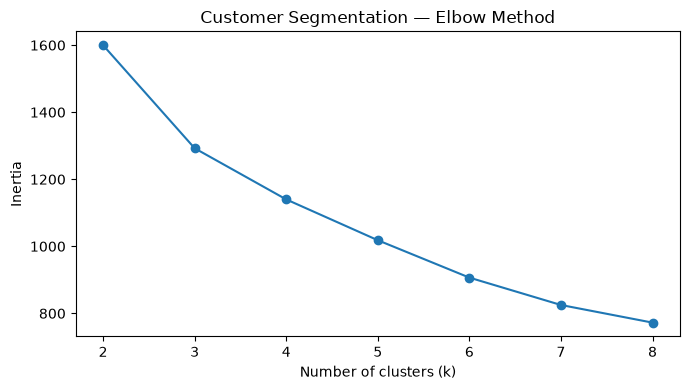

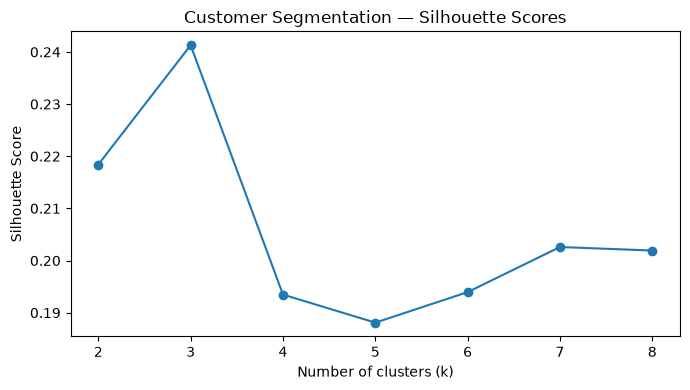

Selected k based on highest tested silhouette score: 3


In [11]:
k_values = range(2, min(9, len(customer_features)))
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

score_table = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})
display(score_table.round(3))

plt.figure(figsize=(7, 4))
plt.plot(score_table["k"], score_table["inertia"], marker="o")
plt.title("Customer Segmentation — Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(OUTPUTS / "customer_elbow_plot.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(score_table["k"], score_table["silhouette_score"], marker="o")
plt.title("Customer Segmentation — Silhouette Scores")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig(OUTPUTS / "customer_silhouette_scores.png", dpi=150)
plt.show()

best_k = int(score_table.loc[score_table["silhouette_score"].idxmax(), "k"])
print("Selected k based on highest tested silhouette score:", best_k)

In [12]:
kmeans_customer = KMeans(n_clusters=best_k, random_state=42, n_init=10)
customer_features["kmeans_cluster"] = kmeans_customer.fit_predict(X_scaled)
joblib.dump(kmeans_customer, MODELS / "customer_kmeans.joblib")

print("K-Means silhouette score:", round(silhouette_score(X_scaled, customer_features["kmeans_cluster"]), 3))
display(customer_features["kmeans_cluster"].value_counts().sort_index().rename("customer_count").to_frame())

K-Means silhouette score: 0.241


,customer_count
kmeans_cluster,
0,163
1,128
2,9


## 7. DBSCAN — Dense groups and noise

DBSCAN groups points in dense regions and labels outliers as `-1`. The data is standardized first because DBSCAN relies on distance. The `eps` value is dataset-dependent, so this is a baseline configuration to inspect, not a universal best setting.

In [13]:
dbscan_customer = DBSCAN(eps=1.5, min_samples=5)
dbscan_labels = dbscan_customer.fit_predict(X_scaled)
customer_features["dbscan_cluster"] = dbscan_labels
joblib.dump(dbscan_customer, MODELS / "customer_dbscan.joblib")

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))
print("DBSCAN dense clusters:", n_clusters_dbscan)
print("DBSCAN noise/outliers:", n_noise)
display(customer_features["dbscan_cluster"].value_counts().sort_index().rename("customer_count").to_frame())

valid_dbscan = dbscan_labels != -1
if len(set(dbscan_labels[valid_dbscan])) >= 2:
    print("DBSCAN silhouette (excluding noise):",
          round(silhouette_score(X_scaled[valid_dbscan], dbscan_labels[valid_dbscan]), 3))
else:
    print("DBSCAN silhouette is not calculated: at least two non-noise clusters are needed.")

DBSCAN dense clusters: 1
DBSCAN noise/outliers: 32


,customer_count
dbscan_cluster,
-1,32
0,268


DBSCAN silhouette is not calculated: at least two non-noise clusters are needed.


## 8. PCA visualization

PCA reduces the standardized features to two dimensions for visualization. It is used here for plotting, not to replace the original feature set used by the clustering models.

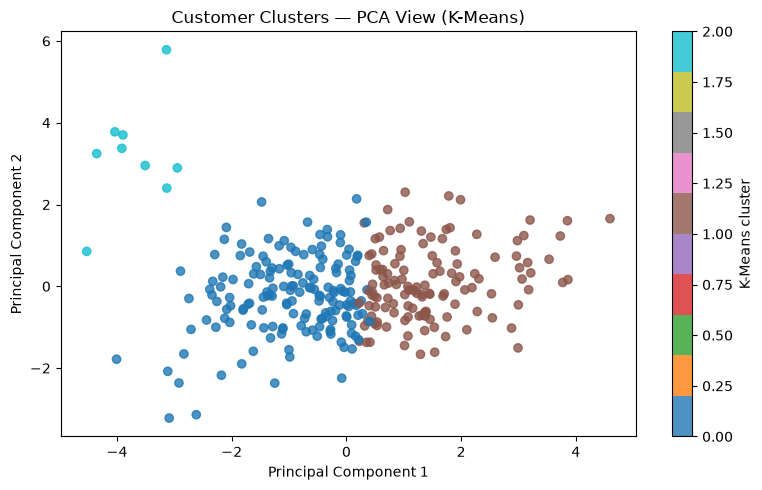

Variance explained by first two components: 0.55


In [14]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
customer_features["pca_1"] = X_pca[:, 0]
customer_features["pca_2"] = X_pca[:, 1]

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    customer_features["pca_1"],
    customer_features["pca_2"],
    c=customer_features["kmeans_cluster"],
    cmap="tab10",
    alpha=0.8
)
plt.title("Customer Clusters — PCA View (K-Means)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="K-Means cluster")
plt.tight_layout()
plt.savefig(OUTPUTS / "customer_pca_kmeans.png", dpi=150)
plt.show()

print("Variance explained by first two components:",
      round(pca.explained_variance_ratio_.sum(), 3))

## 9. Cluster profiles and business names

The table below summarizes the behavioral features for each K-Means cluster. Names are assigned using simple relative rules based on order frequency, spending, and late-night orders. Treat these names as descriptive labels for the synthetic dataset, not as definitive customer identities.

In [15]:
profile = customer_features.groupby("kmeans_cluster")[FEATURES].mean().round(2)
profile["customer_count"] = customer_features.groupby("kmeans_cluster")["customer_id"].count()
profile["share_percent"] = (
    profile["customer_count"] / len(customer_features) * 100
).round(1)

def customer_cluster_name(row, overall):
    if row["total_spending"] >= overall["total_spending"] and row["total_orders"] >= overall["total_orders"]:
        return "Premium Frequent Diners"
    if row["late_night_orders"] >= overall["late_night_orders"] and row["total_spending"] >= overall["total_spending"]:
        return "Late-Night High-Value Customers"
    if row["total_orders"] < overall["total_orders"] and row["average_order_value"] < overall["average_order_value"]:
        return "Occasional Budget Customers"
    if row["average_rating_given"] >= overall["average_rating_given"]:
        return "Engaged Feedback Givers"
    return "Regular / Mixed Customers"

overall = customer_features[FEATURES].mean()
profile["business_name"] = [
    customer_cluster_name(profile.loc[idx], overall) for idx in profile.index
]
display(profile)
profile.to_csv(OUTPUTS / "customer_cluster_profiles.csv")
customer_features.to_csv(PROCESSED / "customer_features_clustered.csv", index=False)

print("Saved: data/processed/customer_features_clustered.csv")
print("Saved cluster profile and plots under outputs/customer_segmentation/")

,total_orders,average_order_value,total_spending,ordering_frequency_per_month,average_rating_given,weekend_orders,late_night_orders,customer_count,share_percent,business_name
kmeans_cluster,,,,,,,,,,
0,4.63,498.14,2057.26,2.80,3.61,1.13,1.13,163,54.3,Occasional Budget Customers
1,8.07,580.97,4155.70,3.74,3.70,2.34,2.67,128,42.7,Premium Frequent Diners
2,1.33,471.42,593.02,33.63,4.26,0.67,0.22,9,3.0,Occasional Budget Customers


Saved: data/processed/customer_features_clustered.csv
Saved cluster profile and plots under outputs/customer_segmentation/


## 10. Export the feature-engineered dataset and review deliverables

The processed CSV includes the row identifier and cluster labels for business interpretation. The identifier was not used as a model feature.

In [17]:
customer_features.to_csv(PROCESSED / "customer_features_clustered.csv", index=False)

print("Deliverables created:")
for path in [
    PROCESSED / "customer_features_clustered.csv",
    OUTPUTS / "customer_cluster_profiles.csv",
    OUTPUTS / "customer_elbow_plot.png",
    OUTPUTS / "customer_silhouette_scores.png",
    OUTPUTS / "customer_pca_kmeans.png",
    MODELS / "customer_standard_scaler.joblib",
    MODELS / "customer_kmeans.joblib",
    MODELS / "customer_dbscan.joblib",
]:
    print(("✓ " if path.exists() else "✗ "), path.relative_to(PROJECT_ROOT))

Deliverables created:
✓  data/processed/customer_features_clustered.csv
✓  outputs/customer_segmentation/customer_cluster_profiles.csv
✓  outputs/customer_segmentation/customer_elbow_plot.png
✓  outputs/customer_segmentation/customer_silhouette_scores.png
✓  outputs/customer_segmentation/customer_pca_kmeans.png
✓  models/customer_standard_scaler.joblib
✓  models/customer_kmeans.joblib
✓  models/customer_dbscan.joblib
